# Assignment 1 - Analysis: basic matrix multiplication in Python, Java and C

**Research question.** How does matrix size $n$ affect the runtime and memory of a
straightforward triple-loop dense matrix multiplication ($O(n^3)$) implemented in
Python, Java and C, under one controlled measurement protocol?

This notebook consumes the raw measurements produced by `scripts/run_benchmark.py`
and produces every table and figure used in the report
(`reports/Assignment01_DelgadoValera_Report.tex`).

- Inputs: `data/results/raw_timings.csv`, `data/results/configs.csv`,
  `data/results/environment.json`, `data/results/correctness_report.csv`
- Outputs: `data/results/summary.csv`, `data/results/limits.csv`,
  `reports/figures/fig{1..5}_*.{pdf,png}`


In [1]:
%matplotlib inline
from __future__ import annotations

import json
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path("..") if (Path("..") / "data").exists() else Path(".")
RES = ROOT / "data" / "results"
FIG = ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 300,
                     "font.size": 10, "axes.grid": True,
                     "grid.alpha": 0.3, "axes.axisbelow": True})

raw = pd.read_csv(RES / "raw_timings.csv")
cfg = pd.read_csv(RES / "configs.csv")
env = json.loads((RES / "environment.json").read_text(encoding="utf-8"))
corr = pd.read_csv(RES / "correctness_report.csv")

BUDGET_S = env["protocol"]["budget_s"]
REPS = env["protocol"]["reps"]
LANGS = ["python", "java", "c"]
COLORS = {"python": "#1f77b4", "java": "#d62728", "c": "#2ca02c"}

print(f"budget = {BUDGET_S} s per multiplication | reps = {REPS} | "
      f"configs = {len(cfg)} | raw timing rows = {len(raw)}")

budget = 60 s per multiplication | reps = 5 | configs = 21 | raw timing rows = 20170


## 1. Environment and protocol

The environment snapshot was taken before the campaign (see `scripts/collect_env.py`).

In [2]:
rows = [
    ("CPU", f"{env['cpu_name'].strip()} | {env['cpu_physical_cores']} physical / "
            f"{env['cpu_logical_cores']} logical processors"),
    ("RAM", f"{env['ram_total_bytes'] / 1e9:.1f} GB"),
    ("OS", env["platform"]),
    ("Python", env["python_version"].split("|")[0].strip()),
    ("Java", env["java_version"].splitlines()[0] if env["java_version"] else ""),
    ("C compiler", f"{env['gcc_version']} (flags: -O2 -std=c11 -Wall -Wextra)"),
    ("NumPy (reference only)", env["numpy_version"]),
    ("Git commit", env["git_commit"][:12] + (" (dirty)" if env["git_dirty"] else "")),
    ("Sizes", ", ".join(map(str, env["protocol"]["sizes"]))),
    ("Warm-ups", f"python/c = {env['protocol']['warmups_python_c']}; "
                 f"java = {env['protocol']['warmups_java']}"),
    ("Java JIT flags", ", ".join(env["protocol"]["java_bench_flags"])),
    ("Timer", "kernel-only, monotonic clock; batch >= 0.2 s per timing"),
]
env_tbl = pd.DataFrame(rows, columns=["Item", "Value"])
env_tbl

,Item,Value
0,CPU,13th Gen Intel(R) Core(TM) i7-1355U | 10 physi...
1,RAM,16.8 GB
2,OS,Windows-10-10.0.26200-SP0
3,Python,"3.11.9 (tags/v3.11.9:de54cf5, Apr 2 2024, 10:..."
4,Java,"openjdk version ""21.0.10"" 2026-01-20 LTS"
5,C compiler,"gcc (MinGW-W64 x86_64-ucrt-mcf-seh, built by B..."
6,NumPy (reference only),2.2.6
7,Git commit,ff5bae3988b0 (dirty)
8,Sizes,"10, 50, 100, 200, 500, 1000, 2000"
9,Warm-ups,"python/c = 1; java = {'n_lt_50': 20000, 'n_le_..."


## 2. Correctness before benchmarking

Cross-language validation (`scripts/check_correctness.py`): 9 cases x 3 languages,
each result compared against NumPy (`float64`) with `rtol = 1e-9`, `atol = 1e-12`,
and compared bit-for-bit between the three implementations.

In [3]:
print(f"comparisons: {len(corr)} | passed: {int(corr['passed'].sum())} | "
      f"failed: {int((~corr['passed']).sum())}")
print("cases:", ", ".join(sorted(corr["case"].unique())))
print("comparison types:", corr["comparison"].value_counts().to_dict())
pw = corr[corr["comparison"] == "pairwise"]
vr = corr[corr["comparison"] == "vs_reference"]
print("tolerances: rtol =", corr["rtol"].max(), "| atol =", corr["atol"].max())
print(f"bitwise equal across languages: {int(pw['bitwise_equal'].sum())}/{len(pw)} pairwise rows")
print(f"bitwise equal vs NumPy: {int(vr['bitwise_equal'].sum())}/{len(vr)} rows "
      "(differences within tolerance come from evaluation order)")
identical = raw[raw["checksum"].notna() & (raw["phase"] != "probe")]
ck = identical.groupby(["lang", "n"])["checksum"].nunique()
print(f"\nchecksums unique per (lang, n): {ck.max()} "
      f"-> {'identical across languages for every n' if ck.max() == 1 else 'MISMATCH'}")

comparisons: 55 | passed: 55 | failed: 0
cases: identity_left_64, identity_right_64, known_3, random_33, random_7, shared_10, shared_100, zero_left_64, zero_right_64
comparison types: {'vs_reference': 27, 'pairwise': 27, 'reference_vs_hand': 1}
tolerances: rtol = 1e-09 | atol = 1e-12
bitwise equal across languages: 27/27 pairwise rows
bitwise equal vs NumPy: 15/27 rows (differences within tolerance come from evaluation order)

checksums unique per (lang, n): 1 -> identical across languages for every n


## 3. Per-configuration statistics

Median and IQR over the measured repetitions (warm-ups excluded), as required by the
common protocol. `status` comes from the orchestrator; timeout configurations have
**no** runtime measurement by design (no invented times).

In [4]:
meas = raw[(raw["phase"] == "measure") & raw["kernel_per_mult_ns"].notna()].copy()
meas["per_ns"] = meas["kernel_per_mult_ns"].astype(float)

stats = []
for (lang, n), g in meas.groupby(["lang", "n"]):
    med = g["per_ns"].median()
    q1, q3 = g["per_ns"].quantile(0.25), g["per_ns"].quantile(0.75)
    stats.append({
        "lang": lang, "n": n, "reps": len(g),
        "median_ns": med, "iqr_ns": q3 - q1,
        "iqr_pct": 100 * (q3 - q1) / med,
        "min_ns": g["per_ns"].min(), "max_ns": g["per_ns"].max(),
        "gflops": 2 * n**3 / med,
    })
summary = pd.DataFrame(stats)

st = cfg.set_index(["lang", "n"])[["status", "probe1_ns", "probe2_ns", "wall_s",
                                   "peak_rss_mb", "sys_cpu_mean_pct"]]
summary = summary.merge(st, left_on=["lang", "n"], right_index=True, how="left")
summary = summary.sort_values(["lang", "n"]).reset_index(drop=True)
summary["median_ms"] = summary["median_ns"] / 1e6
summary["iqr_ms"] = summary["iqr_ns"] / 1e6

out = summary[["lang", "n", "status", "reps", "median_ms", "iqr_ms", "iqr_pct",
               "gflops", "peak_rss_mb", "sys_cpu_mean_pct"]].copy()
for c, d in [("median_ms", 6), ("iqr_ms", 6), ("iqr_pct", 3), ("gflops", 4),
             ("peak_rss_mb", 1), ("sys_cpu_mean_pct", 1)]:
    out[c] = out[c].round(d)
out.to_csv(RES / "summary.csv", index=False)
print(f"summary rows: {len(out)} measured + {int((cfg['status'] != 'ok').sum())} timeouts without timing")
out

summary rows: 17 measured + 4 timeouts without timing


,lang,n,status,reps,median_ms,iqr_ms,iqr_pct,gflops,peak_rss_mb,sys_cpu_mean_pct
0,c,10,ok,5,0.001268,0.000026,2.054,1.5769,4.2,20.8
1,c,50,ok,5,0.101585,0.000583,0.574,2.4610,4.3,15.2
2,c,100,ok,5,0.971413,0.011232,1.156,2.0589,4.5,17.8
3,c,200,ok,5,9.950667,0.079376,0.798,1.6079,5.2,20.1
4,c,500,ok,5,213.854800,10.999500,5.143,1.1690,10.0,25.3
5,c,1000,ok,5,2269.568000,89.357600,3.937,0.8812,27.1,17.2
6,java,10,ok,5,0.001633,0.000044,2.683,1.2249,74.1,39.6
7,java,50,ok,5,0.168105,0.002032,1.209,1.4872,42.4,35.3
8,java,100,ok,5,1.514268,0.034827,2.300,1.3208,42.8,27.7
9,java,200,ok,5,12.170080,0.014007,0.115,1.3147,46.0,23.5


## 4. Runtime scaling vs the cubic model

Figure 1: median kernel time per multiplication against $n$ (log-log) with the IQR
error bars and a reference line proportional to $n^3$. Configurations that exceeded
the 60 s budget are **not** plotted (the protocol forbids inventing times for
timeouts); they are listed in the limits table of Section 7.

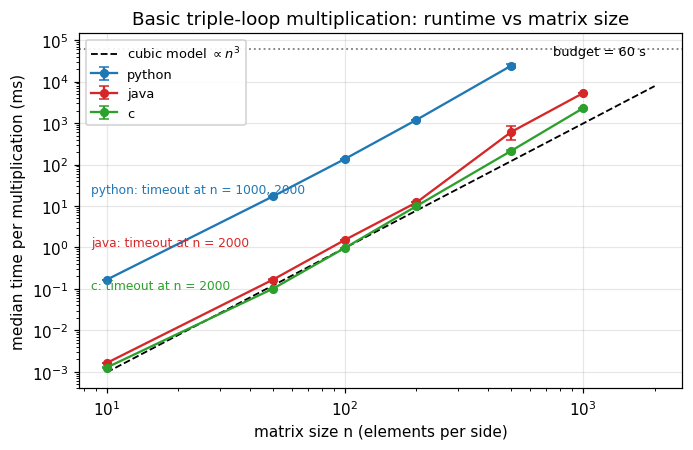

In [5]:
fig, ax = plt.subplots(figsize=(6.4, 4.2))

n_ref = np.array([10, 2000])
for lang in LANGS:
    s = summary[summary["lang"] == lang].sort_values("n")
    ax.errorbar(s["n"], s["median_ms"], yerr=s["iqr_ms"], fmt="o-", capsize=3,
                color=COLORS[lang], label=lang, markersize=5)

ref_base = summary[(summary["lang"] == "c") & (summary["n"] == 100)]["median_ms"].iloc[0]
ax.plot(n_ref, ref_base * (n_ref / 100) ** 3, "k--", lw=1.2,
        label=r"cubic model $\propto n^3$")

ax.axhline(BUDGET_S * 1000, color="gray", ls=":", lw=1.2)
ax.text(750, BUDGET_S * 1000 * 0.72, f"budget = {BUDGET_S} s", fontsize=8.5)

for lang, yoff in [("python", 0.55), ("java", 0.4), ("c", 0.28)]:
    bad = cfg[(cfg["lang"] == lang) & (cfg["status"] != "ok")]["n"]
    if len(bad):
        ax.annotate(f"{lang}: timeout at n = {', '.join(map(str, sorted(bad)))}",
                    xy=(0.02, yoff), xycoords="axes fraction", fontsize=8,
                    color=COLORS[lang])

ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("matrix size n (elements per side)")
ax.set_ylabel("median time per multiplication (ms)")
ax.set_title("Basic triple-loop multiplication: runtime vs matrix size")
ax.legend(loc="upper left", fontsize=8.5, framealpha=0.9)
fig.tight_layout()
for ext in ("pdf", "png"):
    fig.savefig(FIG / f"fig1_runtime_loglog.{ext}")
plt.show()

## 5. Growth exponents and relative speed

Fit $\log T = a + p \log n$ (OLS) per language over its feasible sizes; $p = 3$ is the
algorithmic cubic model, deviations above 3 indicate memory-system effects.
Sizes $n < 100$ are excluded from the fit because fixed call/loop overheads distort the
slope at the small end.

In [6]:
fit_rows = []
for lang in LANGS:
    s = summary[(summary["lang"] == lang) & (summary["n"] >= 100)]
    p, a = np.polyfit(np.log(s["n"]), np.log(s["median_ns"]), 1)
    resid = np.log(s["median_ns"]) - (a + p * np.log(s["n"]))
    fit_rows.append({"lang": lang, "exponent_p": round(p, 3),
                     "R2": round(1 - resid.var() / np.log(s["median_ns"]).var(), 4),
                     "sizes_used": ", ".join(map(str, sorted(s["n"])))})
fit_tbl = pd.DataFrame(fit_rows)
fit_tbl

,lang,exponent_p,R2,sizes_used
0,python,3.223,0.9998,"100, 200, 500"
1,java,3.640,0.9952,"100, 200, 500, 1000"
2,c,3.366,1.0000,"100, 200, 500, 1000"


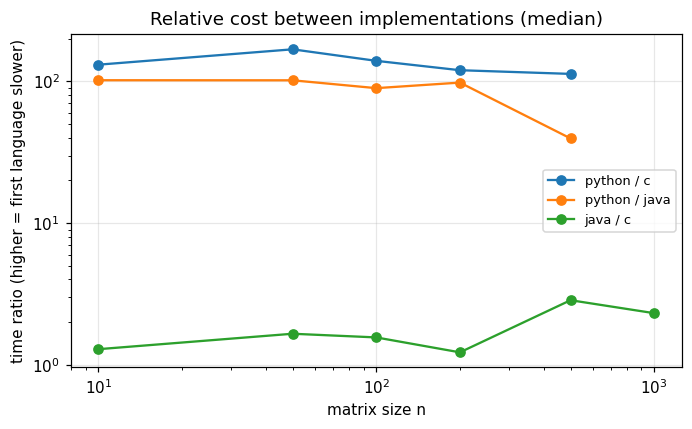

In [7]:
fig, ax = plt.subplots(figsize=(6.4, 4.0))
pairs = [("python", "c"), ("python", "java"), ("java", "c")]
for a_l, b_l in pairs:
    ma = summary[summary["lang"] == a_l].set_index("n")["median_ns"]
    mb = summary[summary["lang"] == b_l].set_index("n")["median_ns"]
    common = ma.index.intersection(mb.index)
    ax.plot(common, (ma[common] / mb[common]), "o-", label=f"{a_l} / {b_l}")

ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("matrix size n")
ax.set_ylabel("time ratio (higher = first language slower)")
ax.set_title("Relative cost between implementations (median)")
ax.legend(fontsize=8.5)
fig.tight_layout()
for ext in ("pdf", "png"):
    fig.savefig(FIG / f"fig2_relative_speed.{ext}")
plt.show()

## 6. Measurement variability

Interquartile range as a percentage of the median for every measured configuration.
Background CPU load during the campaign was sampled every 50 ms by the orchestrator
(`sys_cpu_mean_pct` in `configs.csv`) and is reported next to it as the dominant
noise source on this laptop.

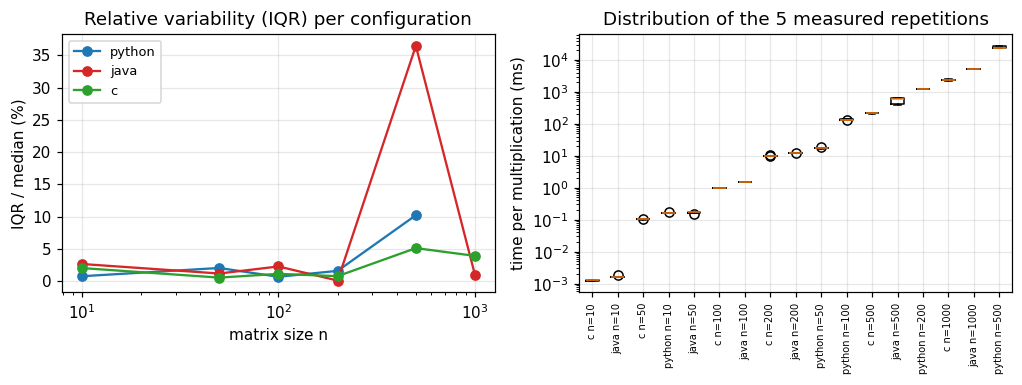

largest IQR: java n=500 -> 36.5% (background CPU mean 29%)
background CPU during campaign: mean 24%, max 100%


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(9.4, 3.6))

for lang in LANGS:
    s = summary[summary["lang"] == lang].sort_values("n")
    axes[0].plot(s["n"], s["iqr_pct"], "o-", color=COLORS[lang], label=lang)
axes[0].set_xscale("log")
axes[0].set_xlabel("matrix size n"); axes[0].set_ylabel("IQR / median (%)")
axes[0].set_title("Relative variability (IQR) per configuration")
axes[0].legend(fontsize=8.5)

sample = meas.copy()
sample["cfg"] = sample["lang"] + " n=" + sample["n"].astype(str)
order = (sample.groupby("cfg")["per_ns"].median().sort_values().index)
axes[1].boxplot([sample[sample["cfg"] == c]["per_ns"] / 1e6 for c in order],
                tick_labels=order, showfliers=True)
axes[1].set_yscale("log")
axes[1].tick_params(axis="x", rotation=90, labelsize=6.5)
axes[1].set_ylabel("time per multiplication (ms)")
axes[1].set_title("Distribution of the 5 measured repetitions")

fig.tight_layout()
for ext in ("pdf", "png"):
    fig.savefig(FIG / f"fig3_variability.{ext}")
plt.show()

worst = summary.loc[summary["iqr_pct"].idxmax()]
print(f"largest IQR: {worst['lang']} n={int(worst['n'])} -> {worst['iqr_pct']:.1f}% "
      f"(background CPU mean {worst['sys_cpu_mean_pct']:.0f}%)")
print(f"background CPU during campaign: mean {cfg['sys_cpu_mean_pct'].mean():.0f}%, "
      f"max {cfg['sys_cpu_max_pct'].max():.0f}%")

## 7. Memory

Metric: **peak resident set size of the child process** sampled every 50 ms by the
orchestrator (psutil on Windows: `peak_wss_bytes` / working set). This includes the
two input matrices, the output matrix, interpreter/JVM/runtime overhead, so it sits
above the theoretical $3 \times 8n^2$ bytes of raw `float64` storage. Java's separate
managed-heap figure is self-reported by the program and is not comparable to the OS
working set (different metrics - not pooled).

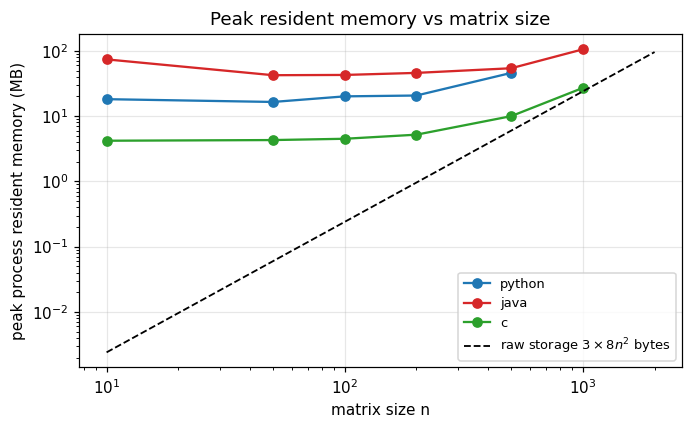

  lang    n  peak_rss_mb
     c  500         10.0
     c 1000         27.1
  java  500         54.2
  java 1000        105.7
python  500         46.0


In [9]:
mem = summary.dropna(subset=["peak_rss_mb"]).copy()
n_line = np.array([10, 2000])
theo = 3 * 8 * n_line**2 / 1e6  # MB

fig, ax = plt.subplots(figsize=(6.4, 4.0))
for lang in LANGS:
    s = mem[mem["lang"] == lang].sort_values("n")
    ax.plot(s["n"], s["peak_rss_mb"], "o-", color=COLORS[lang], label=lang)
ax.plot(n_line, theo, "k--", lw=1.2, label=r"raw storage $3\times 8n^2$ bytes")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("matrix size n")
ax.set_ylabel("peak process resident memory (MB)")
ax.set_title("Peak resident memory vs matrix size")
ax.legend(fontsize=8.5)
fig.tight_layout()
for ext in ("pdf", "png"):
    fig.savefig(FIG / f"fig4_memory.{ext}")
plt.show()

mm = mem[mem["n"].isin([500, 1000])]
print(mm[["lang", "n", "peak_rss_mb"]].to_string(index=False))

## 8. Java warm-up evidence

The first multiplication of a fresh JVM runs largely in the interpreter; the
measurement protocol therefore excludes warm-ups. The curve below replays the
recorded warm-up kernels of the Java `bench` run at $n = 10$ (raw log in
`data/results/raw_detail/java_n10_bench.jsonl`).

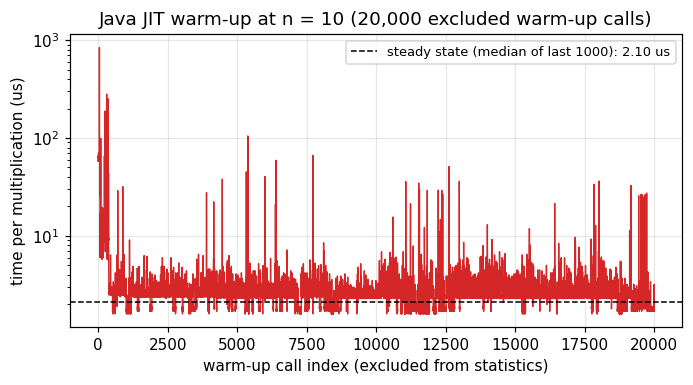

first call: 62.5 us | median of warm-ups 0-19: 58.4 us | steady: 2.10 us


In [10]:
import json as _json

path = RES / "raw_detail" / "java_n10_bench.jsonl"
wu = []
for line in path.read_text(encoding="utf-8").splitlines():
    obj = _json.loads(line)
    if obj.get("mode") == "bench" and obj.get("phase") == "warmup":
        wu.append(obj["kernel_per_mult_ns"])
wu = np.array(wu, dtype=float)

fig, ax = plt.subplots(figsize=(6.4, 3.6))
ax.plot(np.arange(len(wu)), wu / 1e3, lw=0.9, color=COLORS["java"])
ax.axhline(np.median(wu[-1000:]) / 1e3, color="k", ls="--", lw=1,
           label=f"steady state (median of last 1000): {np.median(wu[-1000:]) / 1e3:.2f} us")
ax.set_xlabel("warm-up call index (excluded from statistics)")
ax.set_ylabel("time per multiplication (us)")
ax.set_title("Java JIT warm-up at n = 10 (20,000 excluded warm-up calls)")
ax.set_yscale("log")
ax.legend(fontsize=8.5)
fig.tight_layout()
for ext in ("pdf", "png"):
    fig.savefig(FIG / f"fig5_java_warmup.{ext}")
plt.show()

print(f"first call: {wu[0] / 1e3:.1f} us | median of warm-ups 0-19: "
      f"{np.median(wu[:20]) / 1e3:.1f} us | steady: {np.median(wu[-1000:]) / 1e3:.2f} us")

## 9. Feasibility limits

Largest measured feasible size per language under the declared budget
(60 s per multiplication, 4 GiB memory). Timeouts are reported as limits without
execution times, as the protocol requires.

In [11]:
limit_rows = []
for lang in LANGS:
    ok = summary[(summary["lang"] == lang) & (summary["status"] == "ok")]
    bad = cfg[(cfg["lang"] == lang) & (cfg["status"] != "ok")]
    row = {
        "lang": lang,
        "largest_feasible_n": int(ok["n"].max()) if len(ok) else None,
        "largest_feasible_median_s": round(ok.sort_values("n").iloc[-1]["median_ns"] / 1e9, 3)
        if len(ok) else None,
        "attempted_but_over_budget": ", ".join(
            f"{int(r.n)} ({int(r.probe1_ns / 1e9)} s probe)" for r in bad.itertuples()
            if pd.notna(r.probe1_ns)),
        "killed_before_first_kernel": ", ".join(
            f"{int(r.n)}" for r in bad.itertuples() if pd.isna(r.probe1_ns)),
        "peak_rss_ok_MB": round(ok["peak_rss_mb"].max(), 0) if len(ok) else None,
    }
    limit_rows.append(row)
limits = pd.DataFrame(limit_rows)
limits.to_csv(RES / "limits.csv", index=False)
print(f"budget: {BUDGET_S} s per multiplication | memory limit: 4096 MB")
limits

budget: 60 s per multiplication | memory limit: 4096 MB


,lang,largest_feasible_n,largest_feasible_median_s,attempted_but_over_budget,killed_before_first_kernel,peak_rss_ok_MB
0,python,500,24.193,,"1000, 2000",46.0
1,java,1000,5.246,,2000,106.0
2,c,1000,2.270,2000 (76 s probe),,27.0


## 10. Artifacts produced for the report

- `data/results/summary.csv` - per-configuration medians, IQR, GFLOP/s, memory
- `data/results/limits.csv` - feasibility limits and timeout reasons
- `reports/figures/fig1_runtime_loglog.*` - scaling vs cubic model
- `reports/figures/fig2_relative_speed.*` - time ratios between languages
- `reports/figures/fig3_variability.*` - IQR and repetition distributions
- `reports/figures/fig4_memory.*` - peak resident memory vs $n$
- `reports/figures/fig5_java_warmup.*` - JIT warm-up curve

**Key numbers used in the report** (regenerated every execution of this notebook):

In [12]:
print(out.to_string(index=False))
print()
print(fit_tbl.to_string(index=False))
print()
print(limits.to_string(index=False))

  lang    n status  reps    median_ms      iqr_ms  iqr_pct  gflops  peak_rss_mb  sys_cpu_mean_pct
     c   10     ok     5     0.001268    0.000026    2.054  1.5769          4.2              20.8
     c   50     ok     5     0.101585    0.000583    0.574  2.4610          4.3              15.2
     c  100     ok     5     0.971413    0.011232    1.156  2.0589          4.5              17.8
     c  200     ok     5     9.950667    0.079376    0.798  1.6079          5.2              20.1
     c  500     ok     5   213.854800   10.999500    5.143  1.1690         10.0              25.3
     c 1000     ok     5  2269.568000   89.357600    3.937  0.8812         27.1              17.2
  java   10     ok     5     0.001633    0.000044    2.683  1.2249         74.1              39.6
  java   50     ok     5     0.168105    0.002032    1.209  1.4872         42.4              35.3
  java  100     ok     5     1.514268    0.034827    2.300  1.3208         42.8              27.7
  java  200     ok  